In [9]:
from pathlib import Path
import mne
import pandas as pd
import matplotlib.pyplot as plt

In [10]:
DATA_ROOT = Path(
    r"C:\Users\Fafou\Desktop\Postdoc_UBC\code\EEG_project"
    r"\project1_openneuro\data\ds003061"
)

print("Dataset found:", DATA_ROOT.exists())

Dataset found: True


In [11]:
subjects = sorted(DATA_ROOT.glob("sub-*"))

print("Number of subjects:", len(subjects))
print([s.name for s in subjects])

Number of subjects: 13
['sub-001', 'sub-002', 'sub-003', 'sub-004', 'sub-005', 'sub-006', 'sub-007', 'sub-008', 'sub-009', 'sub-010', 'sub-011', 'sub-012', 'sub-013']


In [12]:
subject = DATA_ROOT / "sub-001"

for file in subject.rglob("*"):
    if file.is_file():
        print(file.relative_to(DATA_ROOT))

sub-001\eeg\sub-001_task-P300_run-1_channels.tsv
sub-001\eeg\sub-001_task-P300_run-1_coordsystem.json
sub-001\eeg\sub-001_task-P300_run-1_eeg.json
sub-001\eeg\sub-001_task-P300_run-1_eeg.set
sub-001\eeg\sub-001_task-P300_run-1_electrodes.tsv
sub-001\eeg\sub-001_task-P300_run-1_events.json
sub-001\eeg\sub-001_task-P300_run-1_events.tsv
sub-001\eeg\sub-001_task-P300_run-2_channels.tsv
sub-001\eeg\sub-001_task-P300_run-2_coordsystem.json
sub-001\eeg\sub-001_task-P300_run-2_eeg.json
sub-001\eeg\sub-001_task-P300_run-2_eeg.set
sub-001\eeg\sub-001_task-P300_run-2_electrodes.tsv
sub-001\eeg\sub-001_task-P300_run-2_events.json
sub-001\eeg\sub-001_task-P300_run-2_events.tsv
sub-001\eeg\sub-001_task-P300_run-3_channels.tsv
sub-001\eeg\sub-001_task-P300_run-3_coordsystem.json
sub-001\eeg\sub-001_task-P300_run-3_eeg.json
sub-001\eeg\sub-001_task-P300_run-3_eeg.set
sub-001\eeg\sub-001_task-P300_run-3_electrodes.tsv
sub-001\eeg\sub-001_task-P300_run-3_events.json
sub-001\eeg\sub-001_task-P300_run-3_

In [13]:
eeg_files = sorted((subject / "eeg").glob("*.set"))

print("Number of EEG files:", len(eeg_files))

for file in eeg_files:
    print(file.name)

Number of EEG files: 3
sub-001_task-P300_run-1_eeg.set
sub-001_task-P300_run-2_eeg.set
sub-001_task-P300_run-3_eeg.set


In [14]:
eeg_file = eeg_files[0]

raw = mne.io.read_raw_eeglab(
    eeg_file,
    preload=True
)

raw

C:\Users\Fafou\AppData\Local\Temp\ipykernel_17992\4093515965.py:3: RuntimeWarning: Unknown types found, setting as type EEG:
temp: ['Temp']
  raw = mne.io.read_raw_eeglab(
C:\Users\Fafou\AppData\Local\Temp\ipykernel_17992\4093515965.py:3: RuntimeWarning: Not setting positions of 14 gsr/misc/resp channels found in montage:
['EXG1', 'EXG2', 'EXG3', 'EXG4', 'EXG5', 'EXG6', 'EXG7', 'EXG8', 'GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = mne.io.read_raw_eeglab(


<RawEEGLAB | sub-001_task-P300_run-1_eeg.set, 79 x 194048 (758.0 s), ~117.0 MiB, data loaded>

In [16]:
print("Sampling frequency:", raw.info["sfreq"], "Hz")
print("Number of channels:", raw.info["nchan"])
print("Duration:", round(raw.times[-1] / 60, 2), "minutes")
print("Channels:")
print(raw.ch_names)
print(raw.annotations)

Sampling frequency: 256.0 Hz
Number of channels: 79
Duration: 12.63 minutes
Channels:
['Fp1', 'AF7', 'AF3', 'F1', 'F3', 'F5', 'F7', 'FT7', 'FC5', 'FC3', 'FC1', 'C1', 'C3', 'C5', 'T7', 'TP7', 'CP5', 'CP3', 'CP1', 'P1', 'P3', 'P5', 'P7', 'P9', 'PO7', 'PO3', 'O1', 'Iz', 'Oz', 'POz', 'Pz', 'CPz', 'Fpz', 'Fp2', 'AF8', 'AF4', 'AFz', 'Fz', 'F2', 'F4', 'F6', 'F8', 'FT8', 'FC6', 'FC4', 'FC2', 'FCz', 'Cz', 'C2', 'C4', 'C6', 'T8', 'TP8', 'CP6', 'CP4', 'CP2', 'P2', 'P4', 'P6', 'P8', 'P10', 'PO8', 'PO4', 'O2', 'EXG1', 'EXG2', 'EXG3', 'EXG4', 'EXG5', 'EXG6', 'EXG7', 'EXG8', 'GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet', 'Temp']
<Annotations | 863 segments: ignore (3), noise (111), noise_with_reponse ...>


In [17]:
events, event_id = mne.events_from_annotations(raw)

print("Event codes:")
print(event_id)

print("\nNumber of events:", len(events))
print("\nFirst 10 events:")
print(events[:10])

Used Annotations descriptions: ['ignore', 'noise', 'noise_with_reponse', 'oddball', 'oddball_with_reponse', 'response', 'standard']
Event codes:
{'ignore': 1, 'noise': 2, 'noise_with_reponse': 3, 'oddball': 4, 'oddball_with_reponse': 5, 'response': 6, 'standard': 7}

Number of events: 863

First 10 events:
[[1139    0    7]
 [1346    0    7]
 [1604    0    7]
 [1876    0    7]
 [2138    0    7]
 [2374    0    7]
 [2629    0    7]
 [2896    0    7]
 [3159    0    7]
 [3420    0    7]]


In [18]:
from collections import Counter

event_counts = Counter(raw.annotations.description)

for event, count in event_counts.items():
    print(f"{event}: {count}")

standard: 522
noise_with_reponse: 1
response: 113
oddball: 1
noise: 111
oddball_with_reponse: 112
ignore: 3


In [19]:
oddball_events = events[events[:, 2] == event_id["oddball"]]

print("Number of oddball events:", len(oddball_events))
print("First 5 oddball events:")
print(oddball_events[:5])

Number of oddball events: 1
First 5 oddball events:
[[4963    0    4]]


In [20]:
oddball_codes = [
    event_id["oddball"],
    event_id["oddball_with_reponse"]
]

oddball_events = events[
    (events[:, 2] == oddball_codes[0]) |
    (events[:, 2] == oddball_codes[1])
]

print("Total oddball trials:", len(oddball_events))

Total oddball trials: 113


In [21]:
noise_codes = [
    event_id["noise"],
    event_id["noise_with_reponse"]
]

noise_events = events[
    (events[:, 2] == noise_codes[0]) |
    (events[:, 2] == noise_codes[1])
]

print("Total noise trials:", len(noise_events))

Total noise trials: 112


In [24]:
epochs = mne.Epochs(
    raw,
    events,
    event_id={
        "standard": event_id["standard"],
        "oddball/no_response": event_id["oddball"],
        "oddball/response": event_id["oddball_with_reponse"],
    },
    tmin=-0.2,
    tmax=0.8,
    baseline=(-0.2, 0),
    preload=True
)

epochs

Not setting metadata
635 matching events found
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 635 events and 257 original time points ...
1 bad epochs dropped


<Epochs | 634 events (all good), -0.199 – 0.801 s (baseline -0.2 – 0 s), ~98.3 MiB, data loaded,
 'standard': 521
 'oddball/no_response': 1
 'oddball/response': 112>

In [26]:
"oddball/no_response"
"oddball/response"
epochs["oddball"]
print("Standard:", len(epochs["standard"]))
print("Oddball:", len(epochs["oddball"]))

Standard: 521
Oddball: 113


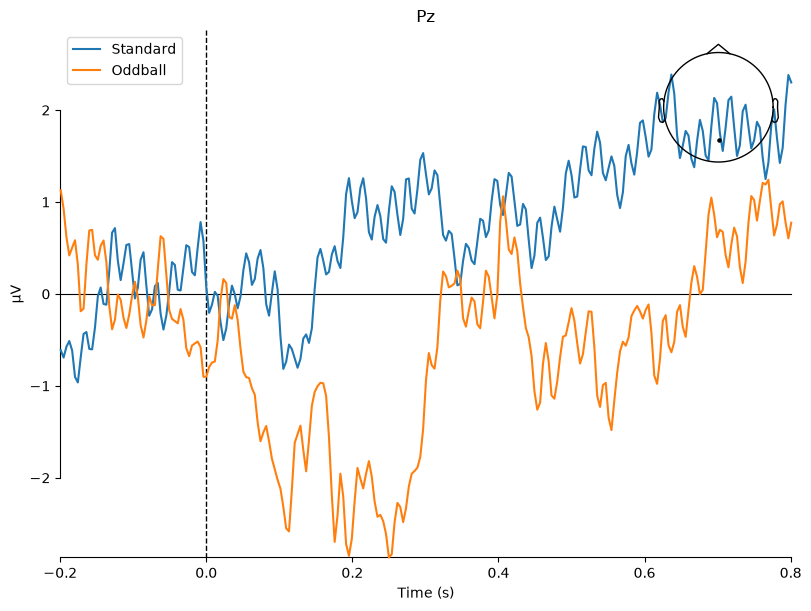

[<Figure size 800x600 with 2 Axes>]

In [27]:
standard_erp = epochs["standard"].average()
oddball_erp = epochs["oddball"].average()
mne.viz.plot_compare_evokeds(
    {
        "Standard": standard_erp,
        "Oddball": oddball_erp
    },
    picks="Pz"
)